# expTM — 25 × 25 control-space refinement

Place this notebook in `exptm/ExpTM_Fresh_Training`, beside notebook 04. Use the same original training/sampling kernel.
Run Cells 1–3 to prepare, then set `RUN_GRID = True` in Cell 4 when ready. Do not rerun training notebooks.

**Bounded question:** What additional density-response structure is resolved by a 25 × 25 grid of the same control ranges and the same trained model?

Frozen design: mean control -5 to 5 (25 values), variance control 1 to 12 (25 values), 128 samples per point in two groups of 64, batch size 16; epoch-10 checkpoint, CPU, four threads, 100 diffusion steps, gamma = eta = 1. No model/source changes.

The grids share 9 locations: means {-5, 0, 5} crossed with variances {1, 6.5, 12}.
These 1,152 existing configurations are reused only after checking the parent protocol and original array checksums. They are not independent replication.
616 new points require 78,848 new configurations. The final map contains 80,000 configurations.
Estimated additional runtime: approximately 14.2 hours on the recorded machine, based on the completed 11 × 11 run; not a guarantee.
The new folder stores about 384 MB of float32 sample arrays, including copied shared points. Keep the original run too.

**Decision rule:** completion means the frozen grid and records are complete, not physical accuracy PASS. Report all outcomes, local reversals, sampling variation and the limits of grid resolution. No fitted physical coordinates, critical-point claim, retraining, seed selection or automatic follow-up.
Stop on numerical errors; preserve them. Manually interrupted work can resume with the same protocol and runtime. No concurrent writers.


## 1 — Locate the original run and verify provenance


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import sys, json, hashlib, random, time, platform, uuid, csv, zipfile
import numpy as np
import torch
import matplotlib.pyplot as plt

# Normally no edits are needed. If there are several epoch-10 runs, set an explicit path.
CHECKPOINT_OVERRIDE = None
# For a MANUALLY INTERRUPTED run, paste the printed output path here and rerun from Cell 1.
RESUME_RUN = None
# Optional: explicit path of the completed 11 x 11 run.
SOURCE_RUN_OVERRIDE = None

candidates = [Path.cwd(), Path.cwd()/"ExpTM_Fresh_Training",
              Path.cwd()/"exptm"/"ExpTM_Fresh_Training"]
ROOT = next((p.resolve() for p in candidates if (p/"training_manifest.json").is_file()), None)
assert ROOT is not None, "Place/open this notebook in exptm/ExpTM_Fresh_Training."

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(1024*1024), b""):
            h.update(chunk)
    return h.hexdigest()

EXPECTED_SOURCE = {'author_training_source/tm/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'author_training_source/tm/architectures/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'author_training_source/tm/architectures/unet_2d_mid_attn.py': '87f662a0474f4beb53d125afc7222b11bb30c9f2840f3e273215f76b3bf8c63c', 'author_training_source/tm/core/__init__.py': 'e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855', 'author_training_source/tm/core/backbone.py': 'e414f5a53c456c1ffb68d910cced0cd49627c2853fe7ff19d26ebd1e2eb040d2', 'author_training_source/tm/core/diffusion_model.py': '849ecf96d9b2e476bffa65e31a56028db4ab82f2db45a89cfc4aa1c1135f6dce', 'author_training_source/tm/core/diffusion_process.py': 'fb4b3c55444d736cb4db3917d663b5a5bd16c27a9a3eaba408abe1a656ae434c', 'author_training_source/tm/core/loader.py': '3ca9e881b03ddbaea1bc1f0c61cdb61e4fa5a92bb347da0f944d84960b3b2e7a', 'author_training_source/tm/core/prior.py': '674a7427efc278ae007cafda823dcb2ebab1fe2070455d33f5968bc54b680abb', 'author_training_source/tm/core/utils.py': 'd5e3f31598342c2aec6b673c786c996082602bd7ca8b645d8e47ac00163b6463', 'data/HighMuT7.npy': 'f4ad83d9bf54fae9753bd3daba7aa861c1fdd25ad927e6a171cf429a1801660b', 'data/LowMuT7.npy': '05802d6a1ea829c19fae8a913501695a981f86a9fe6b3cf47712bbe52e88f4cd'}
EXPECTED_CHECKPOINT = '861577d8d1e0093163be56f7ada681c5b075370921a0f857ba9d57c2b90bb187'
manifest = json.loads((ROOT/"training_manifest.json").read_text())
assert manifest["sha256"] == EXPECTED_SOURCE, "Source/data manifest differs from the recorded training run."
for relative, expected in EXPECTED_SOURCE.items():
    assert sha256(ROOT/relative) == expected, f"Source/data mismatch: {relative}"

if CHECKPOINT_OVERRIDE is None:
    matches = sorted((ROOT/"runs").glob("resume10_*/models/model_9.pt"))
    assert len(matches) == 1, f"Found {len(matches)} candidates. Set CHECKPOINT_OVERRIDE explicitly: {matches}"
    CHECKPOINT = matches[0]
else:
    CHECKPOINT = Path(CHECKPOINT_OVERRIDE).expanduser().resolve()
assert CHECKPOINT.is_file(), CHECKPOINT
assert sha256(CHECKPOINT) == EXPECTED_CHECKPOINT, "This is not the recorded epoch-10 checkpoint."
PARENT_RUN = CHECKPOINT.parent.parent
parent_config = json.loads((PARENT_RUN/"config.json").read_text())
assert parent_config["epochs"] == 10 and parent_config["device"] == "cpu"
assert parent_config["source_and_data_sha256"] == EXPECTED_SOURCE
assert str(torch.__version__) == parent_config["torch_version"], "Select the original training kernel (PyTorch version mismatch)."
assert np.__version__ == parent_config["numpy_version"], "Select the original training kernel (NumPy version mismatch)."
assert parent_config["diffusion_steps"] == 100
assert parent_config["gamma"] == parent_config["eta"] == 1

SOURCE = ROOT/"author_training_source"
for name, module in list(sys.modules.items()):
    if name == "tm" or name.startswith("tm."):
        filename = getattr(module, "__file__", None)
        assert filename and SOURCE in Path(filename).resolve().parents, "Different tm package loaded: restart kernel."
sys.path.insert(0, str(SOURCE))
from tm.core.prior import GlobalEquilibriumHarmonicPrior
from tm.core.backbone import ConvBackbone
from tm.core.diffusion_model import SteeredDiffusionSampler
from tm.core.diffusion_process import VPDiffusion
from tm.architectures.unet_2d_mid_attn import Unet2D
from tm.core.loader import Loader
print("Python:", sys.executable)
print("Checkpoint:", CHECKPOINT)
print("Checkpoint SHA256:", EXPECTED_CHECKPOINT)
print("Source, data, and recorded runtime versions verified. No sampling started.")


Python: c:\Users\user\AppData\Local\Python\pythoncore-3.14-64\python.exe
Checkpoint: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\resume10_20261109T235517Z_058d38a3\models\model_9.pt
Checkpoint SHA256: 861577d8d1e0093163be56f7ada681c5b075370921a0f857ba9d57c2b90bb187
Source, data, and recorded runtime versions verified. No sampling started.


## 2 — Restore the model and original loader construction (no training)


In [2]:
torch.set_num_threads(4)
random.seed(parent_config["seed"])
np.random.seed(parent_config["seed"])
torch.manual_seed(parent_config["seed"])
low = np.load(ROOT/"data/LowMuT7.npy", allow_pickle=False)
high = np.load(ROOT/"data/HighMuT7.npy", allow_pickle=False)
assert low.shape == high.shape == (5000, 2, 20, 20)
coords = np.concatenate([low[:, 0], high[:, 0]], axis=0)
assert np.isin(coords, [-1, 1]).all()
pressures = np.concatenate([-np.ones(len(low)), np.ones(len(high))]).astype(np.float32)
temperatures = np.ones(len(coords), dtype=np.float32)
data = np.empty((len(coords), 3, 20, 20), dtype=np.float32)
data[:, 0] = coords
data[:, 1] = temperatures[:, None, None]
data[:, 2] = pressures[:, None, None]
loader = Loader(data=data, pressures=pressures[:, None], temperatures=temperatures[:, None], control_dims=(1, 3))
assert torch.isfinite(loader.data).all()
loader_digest = hashlib.sha256(loader.data.numpy().tobytes()).hexdigest()
assert loader_digest == parent_config["loader_data_sha256"], "Loader reconstruction differs; do not sample."
prior = GlobalEquilibriumHarmonicPrior(shape=loader.data.shape,
    channels_info={"coordinate": [0], "fluctuation": [1], "mean": [2]})
model = Unet2D(dim=32, dim_mults=(1, 2, 4), resnet_block_groups=8, channels=3)
backbone = ConvBackbone(model=model, data_shape=20, target_shape=32,
    num_dims=4, lr=1e-3, eval_mode="train", self_condition=True)
# Keep the author's backbone behavior and original CPU sampling configuration.
# Backbone.eval_mode and model.eval() are different settings.
backbone.device = "cpu"
backbone.model.to("cpu")
state = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
assert int(state["epoch"]) == 9
backbone.model.load_state_dict(state["model"], strict=True)
del state
backbone.model.eval()
for parameter in backbone.model.parameters():
    parameter.requires_grad_(False)
diffusion = VPDiffusion(num_diffusion_timesteps=100)
sampler = SteeredDiffusionSampler(diffusion, backbone, loader, prior, pred_type="noise")

def model_digest():
    h = hashlib.sha256()
    for name, value in backbone.model.state_dict().items():
        h.update(name.encode()); h.update(value.detach().cpu().numpy().tobytes())
    return h.hexdigest()
WEIGHTS_BEFORE = model_digest()
print("Strict checkpoint load and loader reconstruction passed. No training or sampling started.")


C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\author_training_source\tm\core\loader.py:304: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\python_variable_indexing.cpp:362.)
  self.unstd_control = self.data[self.control_slice][self.batch_slice]
C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\author_training_source\tm\core\loader.py:305: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will res

Strict checkpoint load and loader reconstruction passed. No training or sampling started.


## 3 — Freeze the grid, seeds, and output folder


In [3]:
import shutil

def canonical_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":")).encode()).hexdigest()

EXPECTED_PARENT_PROTOCOL = 'b5a8a90a74cda26807c4ffdef23f432fa2b8ddcf05f26160d1403c6d2e8d9533'
EXPECTED_REUSED_GROUP_HASHES = {'0_0': 'c378bdc4bc0995ed5f347782665aec95dccc2066a179639e1203a4fc75fcfd9d', '0_1': 'be95c5f0b2e5d85ae62d1f2f6916d22739e8268f38ddd2c7490cfa7b7ff03a24', '5_0': 'b345f4c8dfc9954b869aba67364b61673768e3b7ae8d96bc068bef3cfaeb1be1', '5_1': '928eacdbeadcbd344bba690236391353a03896a30fc5bdd2e982c934b5b71fa4', '10_0': '7fc4d37f9bf73249814f2fd227ac43aaaed032fc990e5c5f35ac2f27ac347b70', '10_1': '3e3499df5fb24c51a0a40b0dd5dbd9cccf3c433bdca2affe654b92b30b59da68', '55_0': '98722644bfcb39f79437b78fc5ca4c32ecca422a902fd33d7704e9b9b609a6ed', '55_1': 'a9d3e779d5f0faaa6de5c12ed524238fd70c57ffba44f9f1ee400d68ae43594d', '60_0': '49ef1e50c5d0986d861edf623b0b0b82c7a33122cc565fc7cd19f7a6fbbf9b36', '60_1': '9fae05621e7e566d40ef863325bb9b12d5c813b7866fa979151031b9eae9b539', '65_0': '6305cf9af8346524a1746273fee54aba934a892ff6e26aecfec8d7574308a3e6', '65_1': '2e17b4d1f43ad9f2aae6213b4c5ac999a0bea461123eaffb8277b936545142c1', '110_0': 'a1e1a87f89111a478d285976f4a986347f1369871acac3e5160e72c9a97a9b64', '110_1': '8f51a8da675d633caa31c698b302b9396b7d3c9c63fd5762dda872c8196d48b4', '115_0': '4b98330f5da80401574ce9377b22f1ad469cb96a47455cedb472420d98ae7e33', '115_1': '0ff1c3339b0c77332f465f3ef8b15031175939ee72607285be68bc9c7db42485', '120_0': '1d1223152a7839c114a9dd66c18d50ee670be56899eaf25fc10b1394e79462e2', '120_1': '67c0091ebe8466efa3b4ec6fafe50347a1d9e49866c99f721a327f2a148aa66a'}
if SOURCE_RUN_OVERRIDE is None:
    candidates_11 = []
    for candidate in sorted((ROOT/"runs").glob("control_map_*")):
        f = candidate/"protocol.json"
        if f.is_file() and canonical_hash(json.loads(f.read_text())) == EXPECTED_PARENT_PROTOCOL:
            candidates_11.append(candidate)
    assert len(candidates_11) == 1, f"Set SOURCE_RUN_OVERRIDE to the completed 11x11 run: {candidates_11}"
    SOURCE_RUN = candidates_11[0]
else:
    SOURCE_RUN = Path(SOURCE_RUN_OVERRIDE).expanduser().resolve()
parent_protocol = json.loads((SOURCE_RUN/"protocol.json").read_text())
assert canonical_hash(parent_protocol) == EXPECTED_PARENT_PROTOCOL
parent_status = json.loads((SOURCE_RUN/"status.json").read_text())
assert parent_status["status"] == "completed" and parent_status["completed_points"] == 121
assert parent_status["model_unchanged"] is True
for key, expected in dict(checkpoint_sha256=EXPECTED_CHECKPOINT, torch=str(torch.__version__),
        numpy=np.__version__, python=sys.version, platform=platform.platform(),
        loader_sha256=loader_digest, cpu_threads=4, device="cpu").items():
    assert parent_protocol[key] == expected, f"Original 11x11 protocol mismatch: {key}"

MEAN_VALUES = np.linspace(-5.0, 5.0, 25)
VARIANCE_VALUES = np.linspace(1.0, 12.0, 25)
GROUP_SIZE, GROUPS, BATCH_SIZE = 64, 2, 16
BASE_SEED = 2026112000
points = []
for i, v in enumerate(VARIANCE_VALUES):
    for j, p in enumerate(MEAN_VALUES):
        index = i*25+j
        shared = [q for q in parent_protocol["points"]
                  if np.isclose(q["mean_control"], p, rtol=0, atol=1e-12)
                  and np.isclose(q["variance_control"], v, rtol=0, atol=1e-12)]
        assert len(shared) <= 1
        point = dict(index=index, row=i, col=j, mean_control=float(p), variance_control=float(v),
                     seeds=[BASE_SEED+2*index+r for r in range(2)], reused_parent_index=None)
        if shared:
            old = shared[0]
            point.update(seeds=old["seeds"], reused_parent_index=old["index"])
            for group, seed in enumerate(old["seeds"]):
                stem = f"point_{old['index']:03d}_group_{group}"
                arr = SOURCE_RUN/"raw"/(stem+".npy")
                meta = json.loads((SOURCE_RUN/"raw"/(stem+".json")).read_text())
                expected = EXPECTED_REUSED_GROUP_HASHES[f"{old['index']}_{group}"]
                assert meta["point"] == old and meta["group"] == group and meta["seed"] == seed
                assert meta["sha256"] == expected and sha256(arr) == expected
                x = np.load(arr, allow_pickle=False)
                assert x.shape == (64, 3, 20, 20) and np.isfinite(x).all()
        points.append(point)
assert len(points) == 625
assert sum(p["reused_parent_index"] is not None for p in points) == 9
assert len({s for p in points for s in p["seeds"]}) == 1250
print("Verified 9 shared points against their original sample checksums.")

protocol = dict(task="EXPTM_CONTROL_SPACE_MAP_25_V1", parent_protocol_sha256=EXPECTED_PARENT_PROTOCOL, reused_points=9, new_points=616, new_samples=616*128, checkpoint_sha256=EXPECTED_CHECKPOINT,
    source_and_data_sha256=EXPECTED_SOURCE, points=points, groups_per_point=GROUPS,
    samples_per_group=GROUP_SIZE, batch_size=BATCH_SIZE, gamma=1, eta=1,
    diffusion_steps=100, cpu_threads=4, backbone_eval_mode="train", model_mode="eval",
    loader_sha256=loader_digest, torch=str(torch.__version__), numpy=np.__version__,
    python=sys.version, platform=platform.platform(), device="cpu",
    occupancy_rule="raw coordinate channel >= 0", total_samples=625*128,
    question="What density-response structure is resolved on the fixed 25x25 control grid?",
    interpretation="Exploratory control-space map; no physical parameter mapping or scientific accuracy PASS.",
    stop="Complete the fixed 625-point grid; preserve all outcomes; stop on error; no automatic extensions.")

def write_json(path, value):
    path = Path(path)
    temp = path.with_name(path.name+".tmp")
    temp.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    temp.replace(path)

if RESUME_RUN is None:
    RUN = ROOT/"runs"/("control_map25_"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")+"_"+uuid.uuid4().hex[:8])
    RUN.mkdir(parents=True, exist_ok=False)
    (RUN/"raw").mkdir()
    write_json(RUN/"protocol.json", protocol)
else:
    RUN = Path(RESUME_RUN).expanduser().resolve()
    assert json.loads((RUN/"protocol.json").read_text()) == protocol, "Resume protocol/runtime mismatch."
    if (RUN/"status.json").exists():
        previous_status = json.loads((RUN/"status.json").read_text())
        assert previous_status["status"] != "failed", "Numerical/code error: inspect before resuming."
print("Output directory:", RUN)
print("625 points x 128 configurations; 9 points reused, 616 new. Estimated additional CPU time: ~14.2 hours.")
print("Cell 4 starts sampling only when RUN_GRID is True.")


Verified 9 shared points against their original sample checksums.
Output directory: C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\runs\control_map25_20261110T221306Z_0509da55
625 points x 128 configurations; 9 points reused, 616 new. Estimated additional CPU time: ~14.2 hours.
Cell 4 starts sampling only when RUN_GRID is True.


In [5]:
import hashlib
import numpy as np

snapshot = loader.data.detach().cpu().numpy()
assert hashlib.sha256(snapshot.tobytes()).hexdigest() == \
    parent_config["loader_data_sha256"], "Loader 与原记录不一致"

export_path = ROOT / "carbon_loader_verified.npy"
np.save(export_path, snapshot, allow_pickle=False)
print("已导出：", export_path)

已导出： C:\Users\user\Documents\GitHub\active-matter-reproductions\exptm\ExpTM_Fresh_Training\carbon_loader_verified.npy


## 4 — Generate the fixed grid
Set `RUN_GRID = True` below to start. Keep the computer awake.
The 9 shared points are copied after checksum validation. Each new 64-sample group is saved before continuing. Interrupting inside a group discards only that incomplete group.
For a kernel restart, set `RESUME_RUN` in Cell 1 to the printed output directory and rerun in order.
Completed groups are checked and reused. An error stops the run; do not tune the model or discard inconvenient points.


In [ ]:
RUN_GRID = False  # Change to True when ready to execute this fixed experiment.

def group_paths(point, group):
    stem = f"point_{point['index']:03d}_group_{group}"
    return RUN/"raw"/(stem+".npy"), RUN/"raw"/(stem+".json")

def load_group(point, group):
    path, meta_path = group_paths(point, group)
    meta = json.loads(meta_path.read_text())
    assert meta["point"] == point and meta["group"] == group
    assert meta["seed"] == point["seeds"][group]
    assert sha256(path) == meta["sha256"], f"Saved sample checksum mismatch: {path}"
    raw = np.load(path, allow_pickle=False)
    assert raw.shape == (GROUP_SIZE, 3, 20, 20) and np.isfinite(raw).all()
    return raw, meta

def summarize(point):
    groups = [load_group(point, r) for r in range(GROUPS)]
    rhos = [(raw[:, 0] >= 0).mean(axis=(1, 2)) for raw, _ in groups]
    rho = np.concatenate(rhos)
    return dict(index=point["index"], mean_control=point["mean_control"],
        variance_control=point["variance_control"], samples=len(rho),
        density_mean=float(rho.mean()), density_std=float(rho.std(ddof=1)),
        density_sem=float(rho.std(ddof=1)/np.sqrt(len(rho))),
        group0_mean=float(rhos[0].mean()), group1_mean=float(rhos[1].mean()),
        group_mean_abs_difference=float(abs(rhos[0].mean()-rhos[1].mean())),
        empty_fraction=float(np.mean(rho == 0)), full_fraction=float(np.mean(rho == 1)),
        seconds=sum(meta["seconds"] for _, meta in groups))

def run_grid():
    assert json.loads((RUN/"protocol.json").read_text()) == protocol
    assert model_digest() == WEIGHTS_BEFORE
    if (RUN/"status.json").exists():
        assert json.loads((RUN/"status.json").read_text())["status"] != "failed", "Inspect the previous error first."
    rows = []
    session_started = time.perf_counter()
    write_json(RUN/"status.json", dict(status="running", completed_points=0))
    try:
        for point in points:
            for group, seed in enumerate(point["seeds"]):
                path, meta_path = group_paths(point, group)
                if meta_path.exists():
                    load_group(point, group)
                    continue
                # A sample file with no commit metadata is incomplete: retain it before retry.
                if path.exists():
                    path.rename(path.with_name(path.name+".uncommitted_"+uuid.uuid4().hex[:8]))
                if point["reused_parent_index"] is not None:
                    old_index = point["reused_parent_index"]
                    stem = f"point_{old_index:03d}_group_{group}"
                    source_array = SOURCE_RUN/"raw"/(stem+".npy")
                    source_meta = SOURCE_RUN/"raw"/(stem+".json")
                    old_meta = json.loads(source_meta.read_text())
                    expected = EXPECTED_REUSED_GROUP_HASHES[f"{old_index}_{group}"]
                    assert sha256(source_array) == expected == old_meta["sha256"]
                    temp = path.with_name(path.name+".tmp")
                    shutil.copyfile(source_array, temp)
                    assert sha256(temp) == expected
                    temp.replace(path)
                    write_json(meta_path, dict(point=point, group=group, seed=seed, seconds=0.0,
                        sha256=expected, reused=True, parent_group_seconds=old_meta["seconds"],
                        parent_array=str(source_array), parent_metadata_sha256=sha256(source_meta)))
                    print(f"Point {point['index']+1}/625, group {group+1}/2 reused", flush=True)
                    continue
                random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
                t0 = time.perf_counter()
                with torch.no_grad():
                    raw = sampler.sample_loop(num_samples=GROUP_SIZE, batch_size=BATCH_SIZE,
                        temperature=point["variance_control"], pressure=point["mean_control"], gamma=1, eta=1)
                raw = raw.detach().cpu().numpy()
                if raw.shape != (GROUP_SIZE, 3, 20, 20) or not np.isfinite(raw).all():
                    np.save(RUN/f"invalid_point_{point['index']:03d}_group_{group}.npy", raw)
                    raise FloatingPointError("Invalid generated array; saved for inspection.")
                temp = path.with_name(path.name+".tmp")
                with temp.open("wb") as f: np.save(f, raw, allow_pickle=False)
                temp.replace(path)
                write_json(meta_path, dict(point=point, group=group, seed=seed,
                    seconds=time.perf_counter()-t0, sha256=sha256(path)))
                print(f"Point {point['index']+1}/625, group {group+1}/2 saved", flush=True)
            row = summarize(point); rows.append(row)
            write_json(RUN/"density_summary.json", rows)
            write_json(RUN/"status.json", dict(status="running", completed_points=len(rows)))
            completed_new = [r for r in rows if points[r["index"]]["reused_parent_index"] is None]
            remaining_new = sum(p["reused_parent_index"] is None for p in points[len(rows):])
            eta = (np.mean([r["seconds"] for r in completed_new])*remaining_new/60) if completed_new else float("nan")
            print(f"Completed {len(rows)}/625 | mean={row['mean_control']:+.1f}, variance={row['variance_control']:.1f} | density={row['density_mean']:.5f} | estimated remaining={eta:.1f} min", flush=True)
        assert model_digest() == WEIGHTS_BEFORE, "Model state changed unexpectedly."
        assert sha256(CHECKPOINT) == EXPECTED_CHECKPOINT
        write_json(RUN/"status.json", dict(status="completed", completed_points=len(rows),
            total_samples=625*128, new_samples=616*128, reused_samples=9*128, model_unchanged=True, session_seconds=time.perf_counter()-session_started,
            physical_accuracy_validated=False))
    except BaseException as exc:
        write_json(RUN/"status.json", dict(status="interrupted" if isinstance(exc, KeyboardInterrupt) else "failed",
            completed_points=len(rows), error=repr(exc), session_seconds=time.perf_counter()-session_started))
        raise
    print("Fixed grid completed:", RUN)

if RUN_GRID:
    run_grid()
else:
    print("Prepared only. Set RUN_GRID = True and run this cell to start.")


## 5 — Plot results and prepare a compact review package (no sampling)


In [ ]:
status = json.loads((RUN/"status.json").read_text())
assert status["status"] == "completed", "Finish or resume the grid before producing the final map."
rows = [summarize(point) for point in points]
write_json(RUN/"density_summary.json", rows)
with (RUN/"density_summary.csv").open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
mean_map = np.array([r["density_mean"] for r in rows]).reshape(25, 25)
sem_map = np.array([r["density_sem"] for r in rows]).reshape(25, 25)
group_gap_map = np.array([r["group_mean_abs_difference"] for r in rows]).reshape(25, 25)
np.savez(RUN/"density_arrays.npz", mean_controls=MEAN_VALUES, variance_controls=VARIANCE_VALUES,
    density_mean=mean_map, density_sem=sem_map, group_mean_abs_difference=group_gap_map)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, values, title, upper in zip(axes, [mean_map, sem_map, group_gap_map],
        ["Generated mean density", "Generated-sample SEM", "Absolute difference of group means"], [1, None, None]):
    im = ax.pcolormesh(MEAN_VALUES, VARIANCE_VALUES, values, shading="nearest", cmap="viridis", vmin=0, vmax=upper)
    ax.set_xlabel("Prior mean control"); ax.set_ylabel("Prior variance control")
    ax.set_title(title); fig.colorbar(im, ax=ax)
fig.suptitle("Fixed epoch-10 checkpoint — uncalibrated control space")
fig.savefig(RUN/"control_density_map.png", dpi=180); plt.show()
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
for i in [0, 12, 24]:
    ax.errorbar(MEAN_VALUES, mean_map[i], yerr=sem_map[i], marker="o", capsize=3,
                label=f"Variance control = {VARIANCE_VALUES[i]:.1f}")
ax.set(xlabel="Prior mean control", ylabel="Generated density (mean ± SEM)", ylim=(-.03, 1.03))
ax.legend(); fig.savefig(RUN/"density_slices.png", dpi=180); plt.show()
review_files = ["protocol.json", "status.json", "density_summary.json", "density_summary.csv",
                "density_arrays.npz", "control_density_map.png", "density_slices.png"]
with zipfile.ZipFile(RUN/"control_map25_review.zip", "w", zipfile.ZIP_DEFLATED) as archive:
    for name in review_files: archive.write(RUN/name, name)
    for meta in sorted((RUN/"raw").glob("*.json")): archive.write(meta, "raw_metadata/"+meta.name)
print("Review package:", RUN/"control_map25_review.zip")
print("Preserve the entire run directory, including raw arrays. The compact ZIP omits raw arrays and weights.")
print("Completed exploratory map; no calibrated physical axes or physical accuracy claim.")


## 6 — Compare with author Figure 2 data (optional; plotting only)


In [ ]:
# Optional author comparison: plot only; do not rerun sampling.
figure_dir = ROOT.parent/"ExpTM_Author_Followup"/"author_snapshot"/"GC_Lattice_gas"/"manuscript_figure"
assert figure_dir.is_dir(), f"Author figure folder not found: {figure_dir}"
author_reference = np.load(figure_dir/"org_density_matrix.npy", allow_pickle=False)
author_generated = np.load(figure_dir/"density_matrix.npy", allow_pickle=False)
assert author_reference.shape == (26,26) and author_generated.shape == (25,25)
with np.load(RUN/"density_arrays.npz", allow_pickle=False) as data:
    our_map = data["density_mean"]; means = data["mean_controls"]; variances = data["variance_controls"]
fig, axes = plt.subplots(1,3,figsize=(16,5),constrained_layout=True)
for ax, values, title in zip(axes[:2], [author_reference[:25,:25],author_generated], ["Author reference","Author expTM"]):
    im = ax.imshow(values,origin="lower",aspect="auto",extent=[-20,4,1,13],interpolation="nearest",cmap="viridis",vmin=0,vmax=1)
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Chemical potential (author display axis)"); ax.set_ylabel("Temperature (author display axis)")
axes[1].scatter([-16,0],[7,7],marker="*",s=150,color="red",edgecolors="white")
axes[2].pcolormesh(means,variances,our_map,shading="nearest",cmap="viridis",vmin=0,vmax=1)
axes[2].set_title("Our expTM: 25 x 25 controls",fontweight="bold")
axes[2].set_xlabel("Prior mean control"); axes[2].set_ylabel("Prior variance control")
fig.colorbar(im,ax=list(axes),shrink=.85,label="Mean occupancy density")
fig.suptitle("Author Figure 2 data and our generated map\nShared density scale; physical coordinates are not matched")
fig.savefig(RUN/"figure2_visual_comparison.png",dpi=180,bbox_inches="tight")
fig.savefig(RUN/"figure2_visual_comparison.pdf",bbox_inches="tight")
plt.show()
print("Saved comparison PNG/PDF. Equal grid sizes do not establish physical coordinate correspondence.")


In [1]:
from pathlib import Path
import io
import json
import hashlib
import zipfile
import numpy as np
import matplotlib.pyplot as plt

# Optional: set an explicit local path, e.g. r"C:\Users\user\Downloads\control_map25_review.zip".
REVIEW_ZIP = None

if REVIEW_ZIP is None:
    candidates = [Path.cwd() / "control_map25_review.zip",
                  Path.home() / "Downloads" / "control_map25_review.zip"]
    review_zip = next((p for p in candidates if p.is_file()), None)
    if review_zip is None:
        raise FileNotFoundError("Place control_map25_review.zip beside this notebook, or set REVIEW_ZIP above.")
else:
    review_zip = Path(REVIEW_ZIP).expanduser()

with zipfile.ZipFile(review_zip) as archive:
    carbon_status = json.loads(archive.read("status.json"))
    carbon_protocol = json.loads(archive.read("protocol.json"))
    carbon_rows = json.loads(archive.read("density_summary.json"))
    with np.load(io.BytesIO(archive.read("density_arrays.npz")), allow_pickle=False) as arrays:
        carbon_arrays = {key: arrays[key].copy() for key in arrays.files}

assert carbon_status["status"] == "completed"
assert carbon_status["completed_points"] == len(carbon_rows) == 625
assert carbon_status["total_samples"] == 80000
means = carbon_arrays["mean_controls"]
variances = carbon_arrays["variance_controls"]
density = carbon_arrays["density_mean"]
sem = carbon_arrays["density_sem"]
group_gap = carbon_arrays["group_mean_abs_difference"]
assert means.shape == variances.shape == (25,)
assert np.all(np.diff(means) > 0) and np.all(np.diff(variances) > 0)
for key in ("density_mean", "density_sem", "group_mean_abs_difference"):
    values = carbon_arrays[key]
    assert values.shape == (25, 25) and np.isfinite(values).all()
    expected = np.empty_like(values)
    for row, point in zip(carbon_rows, carbon_protocol["points"]):
        assert row["index"] == point["index"] and row["samples"] == 128
        assert np.isclose(means[point["col"]], row["mean_control"])
        assert np.isclose(variances[point["row"]], row["variance_control"])
        expected[point["row"], point["col"]] = row[key]
    np.testing.assert_allclose(values, expected, rtol=0, atol=0)
assert ((density >= 0) & (density <= 1)).all()
assert (sem >= 0).all() and (group_gap >= 0).all()
reused_points = [p for p in carbon_protocol["points"] if p["reused_parent_index"] is not None]
assert len(reused_points) == 9
print("Completed: 625/625 points; 128 samples per point.")
print(f"New samples: {carbon_status['new_samples']:,}; reused: {carbon_status['reused_samples']:,}")
print(f"Recorded session: {carbon_status['session_seconds'] / 3600:.2f} hours")
print(f"SEM median/max: {np.median(sem):.5f} / {sem.max():.5f}")
print("Review ZIP SHA256:", hashlib.sha256(review_zip.read_bytes()).hexdigest())
print("Summary consistency passed. Raw arrays and model weights are not included in this ZIP.")


Completed: 625/625 points; 128 samples per point.
New samples: 78,848; reused: 1,152
Recorded session: 7.71 hours
SEM median/max: 0.00160 / 0.00598
Review ZIP SHA256: fe30e8cf1ad1ddf9c86aa6e616ece3be2d8c70fa24e2edfd5ec1d7f0eed39c2a
Summary consistency passed. Raw arrays and model weights are not included in this ZIP.


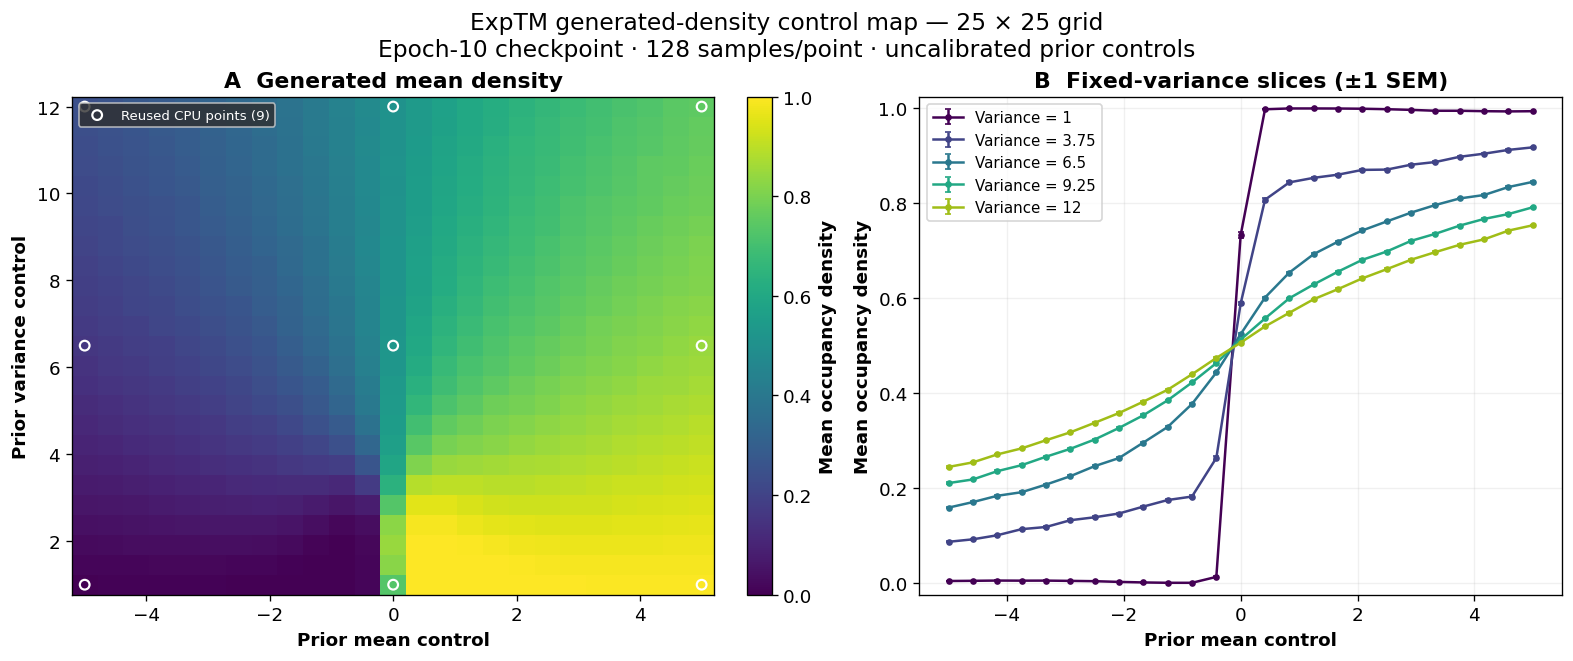

In [2]:
SAVE_FIGURES = False
figure_dir = review_zip.parent / "carbon_figures"

plot_style = {"font.size": 11, "axes.labelweight": "bold", "axes.titleweight": "bold",
              "text.color": "black", "axes.labelcolor": "black", "figure.dpi": 120}

with plt.rc_context(plot_style):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.4), constrained_layout=True)
    mesh = axes[0].pcolormesh(means, variances, density, shading="nearest",
                             cmap="viridis", vmin=0, vmax=1, rasterized=True)
    fig.colorbar(mesh, ax=axes[0], label="Mean occupancy density")
    axes[0].scatter([p["mean_control"] for p in reused_points],
                    [p["variance_control"] for p in reused_points],
                    s=34, facecolors="none", edgecolors="white", linewidths=1.3,
                    label="Reused CPU points (9)")
    axes[0].set(title="A  Generated mean density", xlabel="Prior mean control",
                ylabel="Prior variance control")
    axes[0].legend(loc="upper left", fontsize=8, facecolor="0.18", labelcolor="white")

    # Fixed, evenly spaced rows; no smoothing or fitted phase boundary.
    slice_indices = [0, 6, 12, 18, 24]
    colors = ["#440154", "#414487", "#2a788e", "#22a884", "#a0bd17"]
    for index, color in zip(slice_indices, colors):
        axes[1].errorbar(means, density[index], yerr=sem[index], marker="o",
                         markersize=3, linewidth=1.5, capsize=2, color=color,
                         label=f"Variance = {variances[index]:g}")
    axes[1].set(title="B  Fixed-variance slices (±1 SEM)", xlabel="Prior mean control",
                ylabel="Mean occupancy density", ylim=(-0.025, 1.025))
    axes[1].grid(alpha=0.18)
    axes[1].legend(fontsize=9)
    fig.suptitle("ExpTM generated-density control map — 25 × 25 grid\n"
                 "Epoch-10 checkpoint · 128 samples/point · uncalibrated prior controls", fontsize=14)
    if SAVE_FIGURES:
        figure_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_dir / "carbon_density_map_and_slices.png", dpi=300, bbox_inches="tight")
        print("Saved:", figure_dir / "carbon_density_map_and_slices.png")
    plt.show()


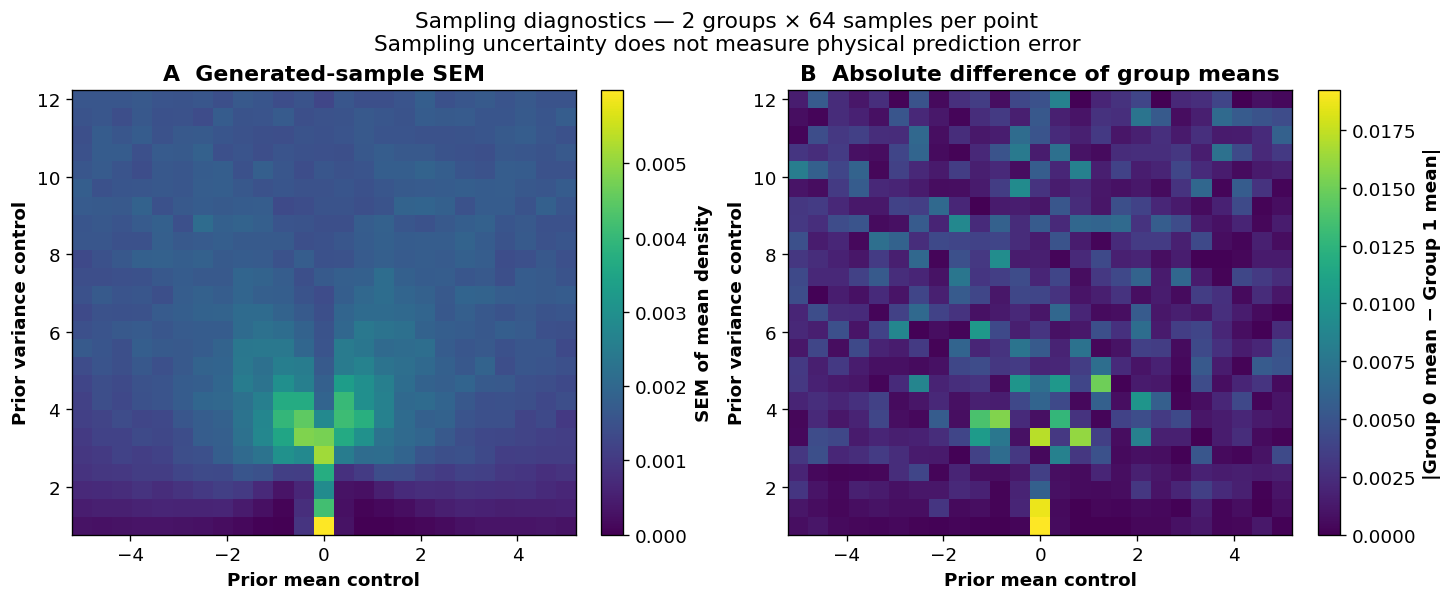

In [4]:
with plt.rc_context(plot_style):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.9), constrained_layout=True)
    for ax, values, title, label in zip(
        axes, [sem, group_gap],
        ["A  Generated-sample SEM", "B  Absolute difference of group means"],
        ["SEM of mean density", "|Group 0 mean − Group 1 mean|"]
    ):
        mesh = ax.pcolormesh(means, variances, values, shading="nearest",
                             cmap="viridis", vmin=0, rasterized=True)
        fig.colorbar(mesh, ax=ax, label=label)
        ax.set(title=title, xlabel="Prior mean control", ylabel="Prior variance control")
    fig.suptitle("Sampling diagnostics — 2 groups × 64 samples per point\n"
                 "Sampling uncertainty does not measure physical prediction error", fontsize=13)
    if SAVE_FIGURES:
        fig.savefig(figure_dir / "carbon_sampling_diagnostics.png", dpi=300, bbox_inches="tight")
        print("Saved:", figure_dir / "carbon_sampling_diagnostics.png")
    plt.show()


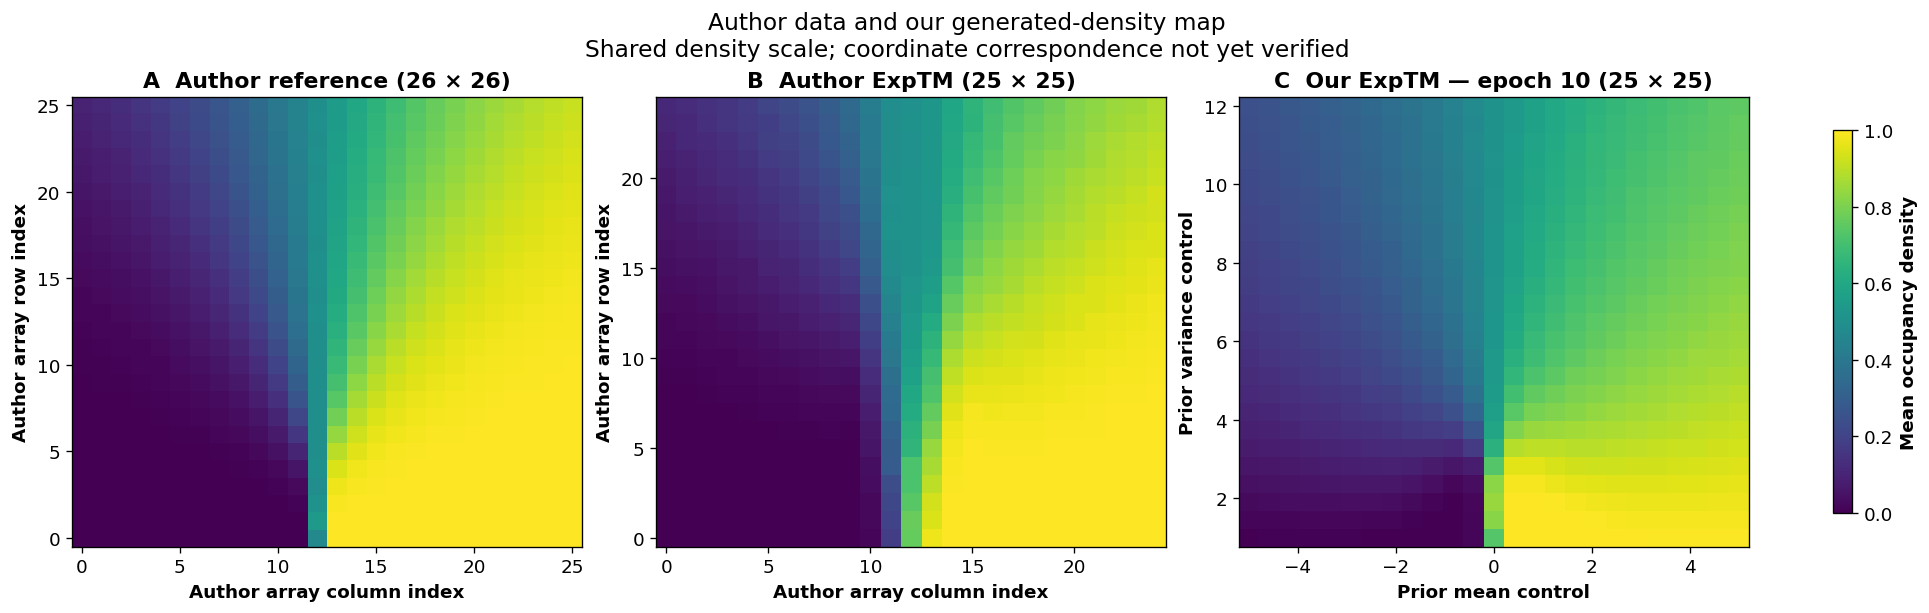

Author reference shape: (26, 26)
Author generated shape: (25, 25)


In [5]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Author Figure 2 data already downloaded to your local project.
author_dir = Path(
    r"C:\Users\user\Documents\GitHub\active-matter-reproductions"
    r"\exptm\ExpTM_Author_Followup\author_snapshot"
    r"\GC_Lattice_gas\manuscript_figure"
)

reference_file = author_dir / "org_density_matrix.npy"
generated_file = author_dir / "density_matrix.npy"

for path in (reference_file, generated_file):
    if not path.is_file():
        raise FileNotFoundError(f"Author data not found: {path}")

author_reference = np.load(reference_file, allow_pickle=False)
author_generated = np.load(generated_file, allow_pickle=False)

# Loaded by the Carbon plotting cells above.
our_density = carbon_arrays["density_mean"]
our_means = carbon_arrays["mean_controls"]
our_variances = carbon_arrays["variance_controls"]

for values in (author_reference, author_generated, our_density):
    assert values.ndim == 2 and np.isfinite(values).all()
    assert ((values >= 0) & (values <= 1)).all()

norm = Normalize(vmin=0, vmax=1)

with plt.rc_context(plot_style):
    fig, axes = plt.subplots(
        1, 3, figsize=(16, 5), constrained_layout=True
    )

    # Keep all author entries. Use array indices until the author's
    # coordinate ordering and physical-axis mapping are verified.
    for ax, values, title in zip(
        axes[:2],
        [author_reference, author_generated],
        ["A  Author reference", "B  Author ExpTM"],
    ):
        ax.imshow(
            values, origin="lower", aspect="auto",
            interpolation="nearest", cmap="viridis", norm=norm,
        )
        ax.set(
            title=f"{title} ({values.shape[0]} × {values.shape[1]})",
            xlabel="Author array column index",
            ylabel="Author array row index",
        )

    mesh = axes[2].pcolormesh(
        our_means, our_variances, our_density,
        shading="nearest", cmap="viridis", norm=norm,
    )
    axes[2].set(
        title="C  Our ExpTM — epoch 10 (25 × 25)",
        xlabel="Prior mean control",
        ylabel="Prior variance control",
    )

    fig.colorbar(
        mesh, ax=list(axes), shrink=0.85,
        label="Mean occupancy density",
    )
    fig.suptitle(
        "Author data and our generated-density map\n"
        "Shared density scale; coordinate correspondence not yet verified",
        fontsize=14,
    )
    plt.show()

print("Author reference shape:", author_reference.shape)
print("Author generated shape:", author_generated.shape)

In [6]:
from pathlib import Path

figure_folder = Path(
    r"C:\Users\user\Documents\GitHub\active-matter-reproductions"
    r"\exptm\ExpTM_Author_Followup\author_snapshot"
    r"\GC_Lattice_gas\manuscript_figure"
)

assert figure_folder.is_dir(), f"Folder not found: {figure_folder}"

for path in sorted(figure_folder.rglob("*")):
    if path.is_file():
        print(path.relative_to(figure_folder))

density_matrix.npy
GC_figure_heatmap.ipynb
org_density_matrix.npy


In [7]:
import os
os.startfile(str(figure_folder))

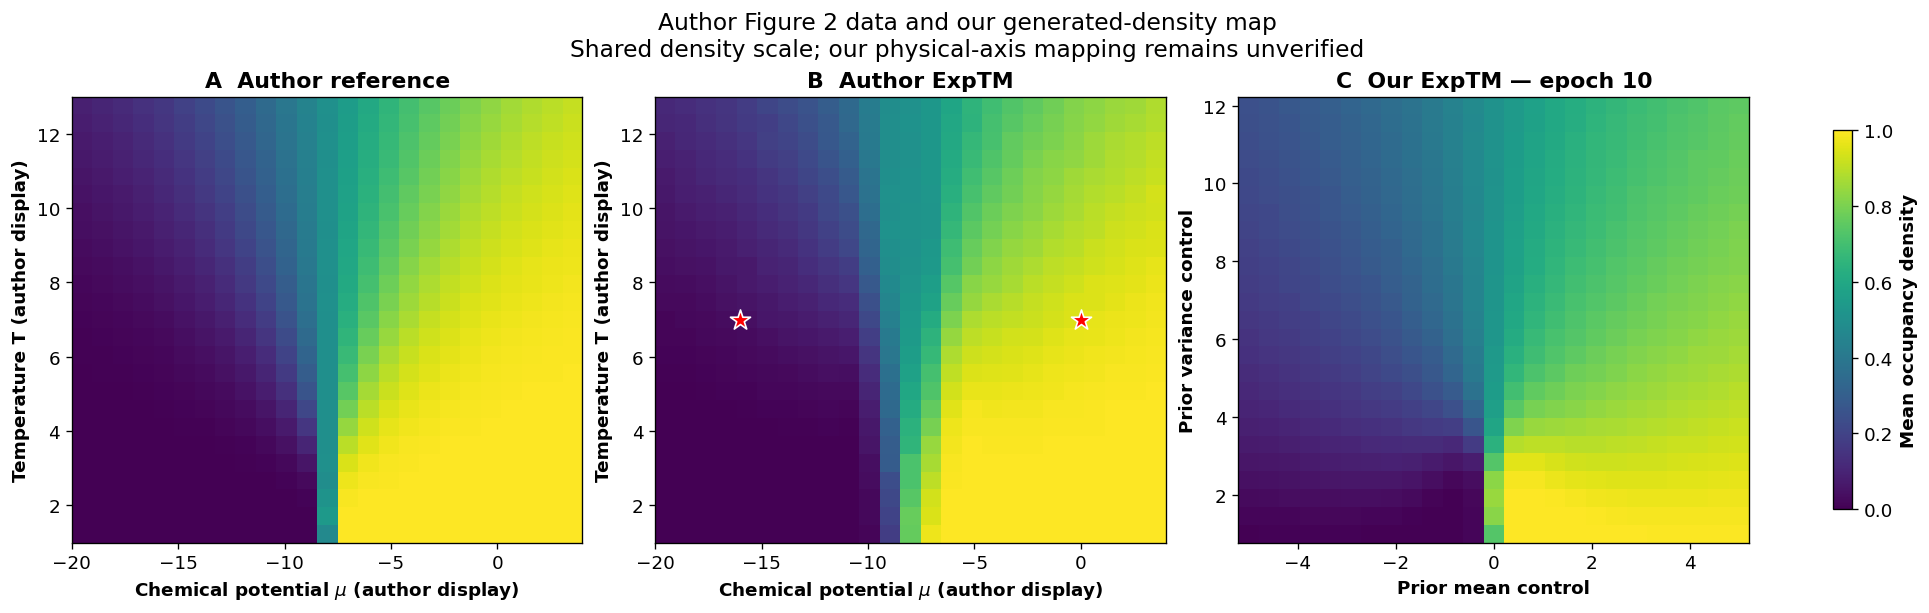

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# figure_folder was defined in the previous cell.
author_ref = np.load(
    figure_folder / "org_density_matrix.npy", allow_pickle=False
)[:25, :25]
author_gen = np.load(
    figure_folder / "density_matrix.npy", allow_pickle=False
)

our_map = carbon_arrays["density_mean"]
our_x = carbon_arrays["mean_controls"]
our_y = carbon_arrays["variance_controls"]

assert author_ref.shape == author_gen.shape == our_map.shape == (25, 25)

# Same density-to-colour mapping for all three panels.
norm = Normalize(vmin=0, vmax=1)
author_extent = [-20, 4, 1, 13]

with plt.rc_context(plot_style):
    fig, axes = plt.subplots(
        1, 3, figsize=(16, 5), constrained_layout=True
    )

    for ax, values, title in zip(
        axes[:2],
        [author_ref, author_gen],
        ["A  Author reference", "B  Author ExpTM"],
    ):
        ax.imshow(
            values,
            origin="lower",
            aspect="auto",
            extent=author_extent,
            interpolation="nearest",
            cmap="viridis",
            norm=norm,
        )
        ax.set(
            title=title,
            xlabel=r"Chemical potential $\mu$ (author display)",
            ylabel="Temperature T (author display)",
        )

    axes[1].scatter(
        [-16, 0], [7, 7],
        marker="*", s=160, color="red", edgecolors="white",
    )

    mesh = axes[2].pcolormesh(
        our_x, our_y, our_map,
        shading="nearest", cmap="viridis", norm=norm,
    )
    axes[2].set(
        title="C  Our ExpTM — epoch 10",
        xlabel="Prior mean control",
        ylabel="Prior variance control",
    )

    fig.colorbar(
        mesh, ax=list(axes), shrink=0.85,
        label="Mean occupancy density",
    )
    fig.suptitle(
        "Author Figure 2 data and our generated-density map\n"
        "Shared density scale; our physical-axis mapping remains unverified",
        fontsize=14,
    )
    plt.show()